In [1]:
import talib
import numpy as np
import pandas as pd
import yfinance as yf
import plotly.graph_objs as go
import plotly.express as px
import time
from tqdm.notebook import tqdm

In [ ]:
sample = yf.download(tickers = "BTC-USD",
                    period = "max",
                    interval ="1d")

In [ ]:
sample.head()

In [ ]:
sample.tail()

In [ ]:
sample['Close'].plot.line(title = 'Close Price for BTC-USD')

In [ ]:
#here we want to define function wrapper
#PARAMETERS
#periods:str
#validate periods: 1d,5d,1mo,3mo,6mo,1y,2,5y,10y,ytd,max
#either we use period parameter or use start and end
#validate intervals :1m,2m,5m,15m,30m,60m,90m,1h,1d,5d,1wk,1mo,3mo
#Intraday data cannot extend last 60 days
def get_stats(ticker = 'BTC-USD',period = '2y',interval = '1h',show_graph = True):
  data = yf.download(tickers = ticker,
                    period = period,
                    interval = interval)
  if isinstance(data.columns, pd.MultiIndex):
      data.columns = data.columns.get_level_values(0)
  if show_graph:
      fig = go.Figure()
      fig.add_trace(go.Candlestick(x =data.index,
                                  open = data['Open'],
                                  high = data['High'],
                                  low = data['Low'],
                                  close = data['Close'],name = 'market data'))
      fig.update_layout(
          title = f'{ticker}live share price evolution',
          yaxis_title =f'{ticker} Price $'
      )
      fig.update_xaxes(
          rangeslider_visible = True,
          rangeselector = dict(
              buttons = list([
                  dict(count = 15,label = "15m",step ="minute",stepmode ="backward"),
                  dict(count = 45,label = "45m",step ="minute",stepmode ="backward"),
                  dict(count = 1,label = "HTD",step ="hour",stepmode ="todate"),
                  dict(count = 6,label = "6h",step = "hour",stepmode ="backward"),
                  dict(step = "all")
              ])
          )
      )
      fig.show()
  return data 

In [ ]:
btc_usd_minute = get_stats('BTC-USD', period = '24h',interval = '1m',show_graph = True)

In [ ]:
btc_usd_hourly = get_stats('BTC-USD',period = '2y',interval ='1h',show_graph = True)

In [ ]:
nvda_hourly = get_stats('NVDA',period = '2y',interval = '1h',show_graph = True)

In [ ]:
bnb_usd_hourly = get_stats('BNB-USD',period = '2y',interval = '1h',show_graph = True)

In [ ]:
bnb_usd_hourly.head()

In [ ]:
qcom_hourly = get_stats('QCOM',period ='2y',interval = '1d',show_graph = True)

In [11]:
from io import StringIO
import pandas as pd
import requests

url = "https://finance.yahoo.com/markets/stocks/most-active/?start=0&count=100"
headers = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"
        " (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    ),
    "Accept-Language": "en-US,en;q=0.9",
}

response = requests.get(url, headers=headers)
response.raise_for_status()  # Raises an error if Yahoo still blocks the IP

yfinance_most_active_stocks_web = pd.read_html(StringIO(response.text))
df = yfinance_most_active_stocks_web[0]
df.head()


,Symbol,Name,Unnamed: 2,Price,Change,Change %,Volume,Avg Vol (3M),Market Cap,P/E Ratio (TTM),52 Wk Change %,52 Wk Range
0,NVDA,NVIDIA Corporation,NaN,159.84 -6.35 (-3.82%),-6.35,-3.82%,365.797M,146.135M,3.932T,20.59,-12.73%,148.80 243.37
1,NU,Nu Holdings Ltd.,NaN,13.09 +1.26 (+10.65%),1.26,+10.65%,152.617M,81.353M,63.965B,16.57,-15.26%,11.20 18.98
2,INTC,Intel Corporation,NaN,57.07 -4.13 (-6.75%),-4.13,-6.75%,102.574M,115.13M,317.093B,--,+71.88%,32.89 142.35
3,CRWV,"CoreWeave, Inc.",NaN,50.75 -5.85 (-10.34%),-5.85,-10.34%,80.146M,45.196M,29.547B,--,-29.47%,40.58 138.25
4,SPCX,Space Exploration Technologies Corp.,NaN,139.02 -0.92 (-0.66%),-0.92,-0.66%,78.515M,95.023M,1.889T,--,-13.57%,104.83 225.64


In [12]:
yfinance_most_active_stocks_web[0]

,Symbol,Name,Unnamed: 2,Price,Change,Change %,Volume,Avg Vol (3M),Market Cap,P/E Ratio (TTM),52 Wk Change %,52 Wk Range
0,NVDA,NVIDIA Corporation,NaN,159.84 -6.35 (-3.82%),-6.35,-3.82%,365.797M,146.135M,3.932T,20.59,-12.73%,148.80 243.37
1,NU,Nu Holdings Ltd.,NaN,13.09 +1.26 (+10.65%),1.26,+10.65%,152.617M,81.353M,63.965B,16.57,-15.26%,11.20 18.98
2,INTC,Intel Corporation,NaN,57.07 -4.13 (-6.75%),-4.13,-6.75%,102.574M,115.13M,317.093B,--,+71.88%,32.89 142.35
3,CRWV,"CoreWeave, Inc.",NaN,50.75 -5.85 (-10.34%),-5.85,-10.34%,80.146M,45.196M,29.547B,--,-29.47%,40.58 138.25
4,SPCX,Space Exploration Technologies Corp.,NaN,139.02 -0.92 (-0.66%),-0.92,-0.66%,78.515M,95.023M,1.889T,--,-13.57%,104.83 225.64
...,...,...,...,...,...,...,...,...,...,...,...,...
95,U,Unity Software Inc.,NaN,52.20 +2.02 (+4.03%),2.02,+4.03%,12.263M,10.991M,23.439B,--,+44.01%,16.78 54.27
96,SNDK,Sandisk Corporation,NaN,838.69 -98.77 (-10.54%),-98.77,-10.54%,12.262M,10.693M,125.928B,7.12,+232.86%,"183.00 2,354.39"
97,NKE,"NIKE, Inc.",NaN,38.06 +0.30 (+0.79%),0.30,+0.79%,12.202M,32.838M,56.427B,18.20,-39.60%,31.97 69.14
98,BTE,Baytex Energy Corp.,NaN,4.37 +0.04 (+0.92%),0.04,+0.92%,12.177M,17.849M,2.937B,--,+44.04%,2.96 5.61


In [13]:
yfinance_most_active_stocks_web[0].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Symbol           100 non-null    object 
 1   Name             100 non-null    object 
 2   Unnamed: 2       0 non-null      float64
 3   Price            100 non-null    object 
 4   Change           100 non-null    float64
 5   Change %         100 non-null    object 
 6   Volume           100 non-null    object 
 7   Avg Vol (3M)     100 non-null    object 
 8   Market Cap       100 non-null    object 
 9   P/E Ratio (TTM)  100 non-null    object 
 10  52 Wk Change %   100 non-null    object 
 11  52 Wk Range      100 non-null    object 
dtypes: float64(2), object(10)
memory usage: 9.5+ KB


In [14]:
FIELDS = ['Symbol','Name','Volume']
stock_tickers = yfinance_most_active_stocks_web[0][FIELDS]

In [15]:
stock_tickers.head()

,Symbol,Name,Volume
0,NVDA,NVIDIA Corporation,365.797M
1,NU,Nu Holdings Ltd.,152.617M
2,INTC,Intel Corporation,102.574M
3,CRWV,"CoreWeave, Inc.",80.146M
4,SPCX,Space Exploration Technologies Corp.,78.515M


In [16]:
%%time
stocks_df = None

for elem in stock_tickers.Symbol.to_list():
  print(f'Downloading stats for this stock {elem}')
  one_ticker_df = get_stats(elem, period='2y', interval='1h', show_graph=False) #do not show the graph
  one_ticker_df['Date'] = one_ticker_df.index
  one_ticker_df['Ticker'] = elem
  if stocks_df is None:
    stocks_df = one_ticker_df
  else:
    stocks_df = pd.concat([stocks_df,one_ticker_df], ignore_index=True, axis=0)
  time.sleep(1) #sleep a bit before downloading next currency

[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed


... (91 outputs left out)

[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed


CPU times: user 13 s, sys: 3.21 s, total: 16.2 s
Wall time: 5min 55s


In [17]:
stocks_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 328097 entries, 0 to 328096
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Close      328097 non-null  float64
 1   High       328097 non-null  float64
 2   Low        328097 non-null  float64
 3   Open       328097 non-null  float64
 4   Volume     328097 non-null  float64
 5   Date       328097 non-null  object 
 6   Ticker     328097 non-null  object 
 7   Adj Close  0 non-null       float64
dtypes: float64(6), object(2)
memory usage: 20.0+ MB


In [18]:
stocks_df.Ticker.value_counts()

Ticker
ASTS    3486
GGB     3486
CLF     3486
S       3486
F       3486
        ... 
CCC     1810
WSE      916
CBRS     893
SPCX     754
SKHY     623
Name: count, Length: 99, dtype: int64

In [19]:
stocks_df["Date"] = pd.to_datetime(stocks_df["Date"], utc=True)
stocks_df['hour'] = stocks_df["Date"].dt.hour

In [20]:
stocks_df['ticker_type'] = 'stock'

In [21]:
print(f'Stocks trading during hours {stocks_df.hour.min()} and {stocks_df.hour.max()}')

Stocks trading during hours 13 and 20


In [22]:
stocks_df.head()

Price,Close,High,Low,Open,Volume,Date,Ticker,Adj Close,hour,ticker_type
0,148.315201,148.570007,145.744995,147.289993,54272218.0,2024-11-14 14:30:00+00:00,NVDA,NaN,14,stock
1,148.865005,148.990005,147.690002,148.309998,25106650.0,2024-11-14 15:30:00+00:00,NVDA,NaN,15,stock
2,147.755005,149.000000,147.671204,148.875000,18098271.0,2024-11-14 16:30:00+00:00,NVDA,NaN,16,stock
3,147.427505,147.869995,147.270004,147.753906,16034380.0,2024-11-14 17:30:00+00:00,NVDA,NaN,17,stock
4,146.802597,147.520004,146.470001,147.429993,25311371.0,2024-11-14 18:30:00+00:00,NVDA,NaN,18,stock


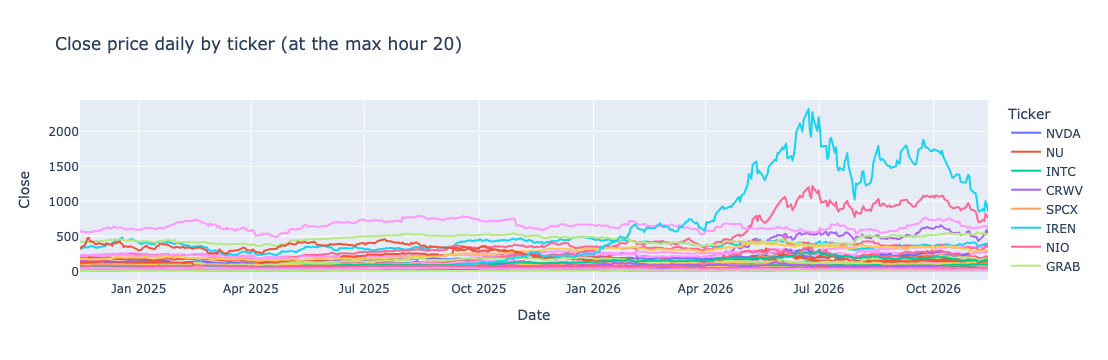

In [23]:
px.line(stocks_df[stocks_df.hour ==15], x='Date', y='Close', color='Ticker', title = f'Close price daily by ticker (at the max hour {stocks_df.hour.max()})' )


In [ ]:
#url = "https://finance.yahoo.com/crypto/"
#headers = {
    #"User-Agent": (
    #    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"
   #     " (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
  #  ),
 #   "Accept-Language": "en-US,en;q=0.9",
#}
#response = requests.get(url, headers = headers)
#response.raise_for_status()  # Raises an error if Yahoo still blocks the IP

#yfinance_crypto_web = pd.read_html(StringIO(response.text))
#df = yfinance_crypto_web[0]
#df.head()


In [ ]:
#from io import StringIO
#import pandas as pd
#import requests

#url = "https://finance.yahoo.com/crypto/"
#headers = {
    #"User-Agent": (
     #   "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"
    #    " (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
   # ),
  #  "Accept-Language": "en-US,en;q=0.9",
#}

#response = requests.get(url, headers=headers)
#response.raise_for_status()  # Raises an error if Yahoo still blocks the IP

#yfinance_crypto_web = pd.read_html(StringIO(response.text))
#df = yfinance_crypto_web[0]
#df.head()

In [ ]:
#from yfinance import EquityQuery

# Query top cryptocurrencies sorted by 24h volume
#query = EquityQuery("eq", ["exchange", "CCC"])
#response = yf.screen(query, sortField="dayvolume", sortAsc=False, size=100)

#yfinance_crypto_web = pd.DataFrame(response["quotes"])
#yfinance_crypto_web.head()



In [24]:
response = yf.screen("all_cryptocurrencies_us", count=100)
yfinance_crypto_web = pd.DataFrame(response["quotes"])
yfinance_crypto_web.head()


,language,region,quoteType,typeDisp,quoteSourceName,triggerable,customPriceAlertConfidence,currency,regularMarketChangePercent,exchange,...,totalSupply,logoUrl,corporateActions,fiftyTwoWeekLowChange,fiftyTwoWeekLowChangePercent,fiftyTwoWeekRange,fiftyTwoWeekHighChange,fiftyTwoWeekHighChangePercent,fiftyTwoWeekChangePercent,symbol
0,en-US,US,CRYPTOCURRENCY,Cryptocurrency,CoinMarketCap,False,LOW,USD,0.250146,CCC,...,20112712,https://s2.coinmarketcap.com/static/img/coins/...,[],6839.894500,0.118444,57747.766 - 97860.6,-33272.940000,-0.340003,-31.906939,BTC-USD
1,en-US,US,CRYPTOCURRENCY,Cryptocurrency,CoinMarketCap,False,LOW,USD,1.084515,CCC,...,122224472,https://s2.coinmarketcap.com/static/img/coins/...,[],304.514280,0.202133,1506.5057 - 3446.6228,-1635.602800,-0.474552,-42.799620,ETH-USD
2,en-US,US,CRYPTOCURRENCY,Cryptocurrency,CoinMarketCap,False,LOW,USD,-0.035021,CCC,...,184269012992,https://s2.coinmarketcap.com/static/img/coins/...,[],0.009483,0.009583,0.989577 - 1.003483,-0.004423,-0.004408,0.016308,USDT-USD
3,en-US,US,CRYPTOCURRENCY,Cryptocurrency,CoinMarketCap,False,LOW,USD,-0.081311,CCC,...,131510520,https://s2.coinmarketcap.com/static/img/coins/...,[],51.220764,0.095100,538.59924 - 954.85834,-365.038330,-0.382296,-37.301342,BNB-USD
4,en-US,US,CRYPTOCURRENCY,Cryptocurrency,CoinMarketCap,False,LOW,USD,0.008235,CCC,...,69071740928,https://s2.coinmarketcap.com/static/img/coins/...,[],0.001929,0.001933,0.997947 - 1.003325,-0.003449,-0.003438,-0.007600,USDC-USD
